# 5b – Soft clustering with Gaussian Mixture Models

The second companion notebook to Example 5. After the embeddings have been reduced to a handful of dimensions (notebook 5a), RAPTOR clusters them with a Gaussian Mixture Model. The paper explains the choice:

> One of the unique aspects of our clustering approach is the use of soft clustering, where nodes can belong to multiple clusters without requiring a fixed number of clusters. This flexibility is essential because individual text segments often contain information relevant to various topics, thereby warranting their inclusion in multiple summaries.
>
> Given a set of $N$ text segments, each represented as a $d$-dimensional dense vector embedding, the likelihood of a text vector, $\mathbf{x}$, given its membership in the $k^{th}$ Gaussian distribution, is denoted by $P(\mathbf{x}|k)=\mathcal{N}(\mathbf{x};\mu_k,\Sigma_k)$. The overall probability distribution is a weighted combination $P(\mathbf{x})=\sum_{k=1}^{K}\pi_k\mathcal{N}(\mathbf{x};\mu_k,\Sigma_k)$, where $\pi_k$ signifies the mixture weight for the $k^{th}$ Gaussian distribution.

Three properties make a mixture attractive compared with, say, k-means:

1. **Soft membership.** Every point gets a probability for every cluster, so a chunk about a note payable secured by a vehicle can feed both the debt summary and the fixed-assets summary.
2. **Shape.** Every cluster has its own covariance matrix, so clusters may be elongated, tilted and of different sizes.
3. **A likelihood.** A mixture is a probability model of the data. That makes it possible to compare models with different numbers of clusters – the topic of notebook 5c.

This notebook builds the model up from a single Gaussian, fits a mixture by hand with the Expectation–Maximisation (EM) algorithm, compares the result with scikit-learn, and ends with the 30 leaves of notebook 5. The early sections use synthetic data drawn from a mixture we define ourselves: then we know the right answer and can check that the method finds it.

## Imports

- `numpy`, `matplotlib`, and `Ellipse` from `matplotlib.patches` to draw a Gaussian's contours.
- `scipy.stats.multivariate_normal` – the density $\mathcal{N}(x;\mu,\Sigma)$, used by our own EM implementation (SciPy is installed as a dependency of scikit-learn).
- `sklearn.mixture.GaussianMixture` – scikit-learn's mixture model, the one RAPTOR and notebook 5 use.
- `sklearn.cluster.KMeans` and `sklearn.datasets.make_blobs` – for the comparison with k-means.
- `umap`, LangChain's splitters and `OllamaEmbeddings` – for the real data at the end.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import umap
from langchain_ollama import OllamaEmbeddings
from langchain_text_splitters import MarkdownHeaderTextSplitter, RecursiveCharacterTextSplitter
from matplotlib.patches import Ellipse
from scipy.stats import multivariate_normal
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.mixture import GaussianMixture

## Configuration

- `SEED` – every random draw and every model uses it, so the notebook gives the same results on every run.
- `TRUE_WEIGHTS`, `TRUE_MEANS`, `TRUE_COVARIANCES` – the *ground truth*: a mixture of three 2-D Gaussians we will sample from. Component 0 is round and the most frequent (weight 0.45), component 1 is tilted and elongated (0.35), component 2 is narrow and the rarest (0.20). Components 1 and 2 overlap a little, on purpose.
- `N_POINTS = 500` – the sample size.
- `DATA_FILE`, `EMBEDDING_MODEL`, `CHUNK_SIZE`, `MIN_CHARS` – notebook 5's settings, to rebuild its 30 leaves in the last section.
- `THRESHOLD = 0.1` – RAPTOR's soft-membership threshold: a point joins every cluster whose probability exceeds it.
- `COLORS` – one colour per component, used consistently in all figures.

In [2]:
SEED = 0
N_POINTS = 500

TRUE_WEIGHTS = np.array([0.45, 0.35, 0.20])
TRUE_MEANS = np.array([[-2.5, 0.0], [1.5, 2.0], [1.8, -1.2]])
TRUE_COVARIANCES = np.array([
    [[1.0, 0.0], [0.0, 1.0]],
    [[1.6, 1.0], [1.0, 1.1]],
    [[0.35, 0.0], [0.0, 0.9]],
])

DATA_FILE = Path("data/document_a.md")
EMBEDDING_MODEL = "embeddinggemma:300m"
CHUNK_SIZE = 1200
MIN_CHARS = 80
THRESHOLD = 0.1

COLORS = plt.get_cmap("tab10").colors
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10})

### Drawing a Gaussian

The density of a 2-D Gaussian has elliptical contours, and `draw_ellipse(ax, mean, covariance, color)` draws two of them. `np.linalg.eigh(covariance)` decomposes the symmetric covariance matrix into eigenvalues – the variances along the ellipse's own axes, smallest first – and eigenvectors, the directions of those axes. The half-axes of the ellipse are the square roots of the eigenvalues (the standard deviations along the axes), and its rotation is the angle of the eigenvector that belongs to the largest eigenvalue. The solid line is drawn at one standard deviation (1σ), the dashed line at two (2σ).

In [3]:
def draw_ellipse(ax, mean, covariance, color, lw=2.0):
    variances, directions = np.linalg.eigh(covariance)
    angle = np.degrees(np.arctan2(directions[1, 1], directions[0, 1]))
    for radius, style in [(1, "-"), (2, "--")]:
        ax.add_patch(Ellipse(mean, 2 * radius * np.sqrt(variances[1]), 2 * radius * np.sqrt(variances[0]),
                             angle=angle, fill=False, color=color, ls=style,
                             lw=lw if radius == 1 else lw / 2))

## 1. One Gaussian

A Gaussian in *d* dimensions is fixed by its **mean** $\mu$ (a *d*-vector: where it sits) and its **covariance matrix** $\Sigma$ (a symmetric *d* × *d* matrix: its shape). Its density is

$$\mathcal{N}(x;\mu,\Sigma)=\frac{1}{\sqrt{(2\pi)^d\,|\Sigma|}}\;\exp\!\Big(-\tfrac12\,(x-\mu)^\top\Sigma^{-1}(x-\mu)\Big).$$

The expression in the exponent, $(x-\mu)^\top\Sigma^{-1}(x-\mu)$, is the squared *Mahalanobis distance*: the distance from the mean measured in standard deviations along the ellipse's axes. Its level sets are the ellipses we draw. The diagonal of $\Sigma$ holds the variances along the coordinate axes; the off-diagonal entries hold the covariance between the coordinates, which tilts the ellipse. The determinant $|\Sigma|$ is the squared area of the ellipse (up to a constant) and sits in the normalisation, so a narrow Gaussian has a high peak – keep that in mind for notebook 5c.

Three examples with 400 samples each: round, stretched along the x-axis, and tilted. The `einsum` expression computes all samples' squared Mahalanobis distances at once, so we can count how many fall inside the 1σ ellipse.

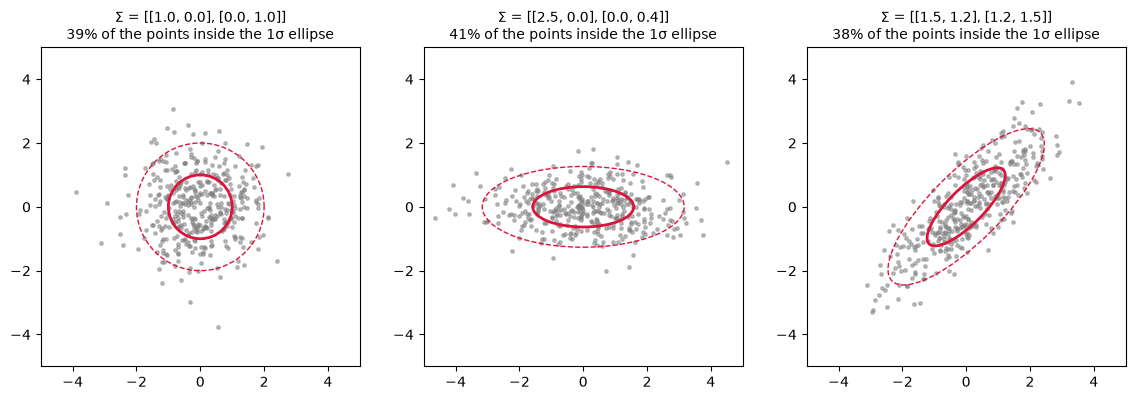

In [4]:
rng = np.random.default_rng(SEED)
examples = [np.array([[1.0, 0.0], [0.0, 1.0]]), np.array([[2.5, 0.0], [0.0, 0.4]]), np.array([[1.5, 1.2], [1.2, 1.5]])]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.7))
for ax, covariance in zip(axes, examples):
    points = rng.multivariate_normal([0, 0], covariance, size=400)
    inside = (np.einsum("ij,jk,ik->i", points, np.linalg.inv(covariance), points) <= 1).mean()
    ax.scatter(points[:, 0], points[:, 1], s=6, alpha=0.5, color="gray")
    draw_ellipse(ax, [0, 0], covariance, "crimson")
    ax.set_title(f"Σ = {covariance.tolist()}\n{inside:.0%} of the points inside the 1σ ellipse")
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.set_aspect("equal")
plt.show()

A detail that surprises most people: in two dimensions only about 39% of the points lie inside the 1σ ellipse, whereas in one dimension 68% lie within ±1σ. The share inside Mahalanobis radius *r* is $1-e^{-r^2/2}$ in 2-D: 39% for *r* = 1 and 86% for *r* = 2. In more dimensions it drops further – almost all of the mass of a high-dimensional Gaussian lies far from its centre.

## 2. A mixture of Gaussians

A mixture describes data that comes from several groups. Its generative story has two steps: pick a component *k* with probability $\pi_k$ (the weights add up to 1), then draw the point from that component's Gaussian. The density of the result is the weighted sum of the components:

$$p(x)=\sum_{k=1}^{K}\pi_k\,\mathcal{N}(x;\mu_k,\Sigma_k).$$

`sample_mixture(n, seed)` follows the story literally: `rng.choice` picks a component for every point according to the weights, and `rng.multivariate_normal` draws the point. It also returns which component generated each point – information a clustering algorithm never gets. The right panel evaluates $p(x)$ on a grid with `multivariate_normal(mean, covariance).pdf`: the landscape the points were drawn from.

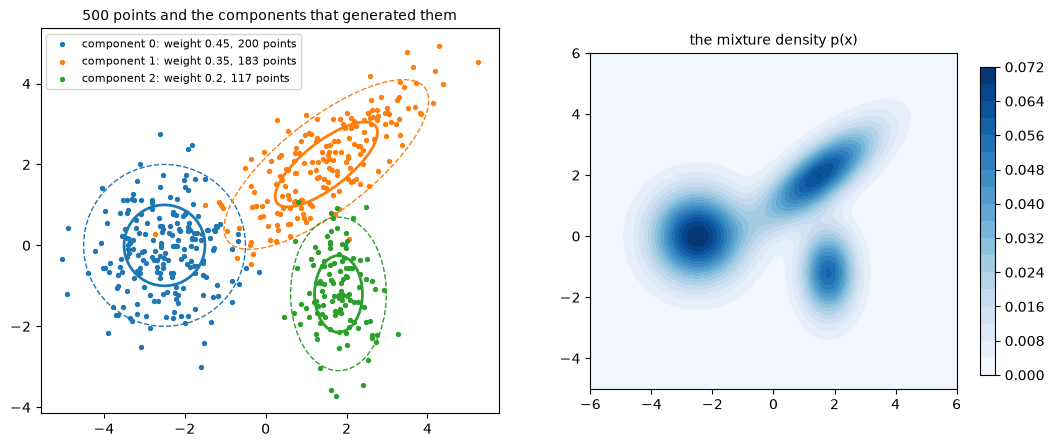

In [5]:
def sample_mixture(n, seed):
    rng = np.random.default_rng(seed)
    components = rng.choice(len(TRUE_WEIGHTS), size=n, p=TRUE_WEIGHTS)
    points = np.array([rng.multivariate_normal(TRUE_MEANS[k], TRUE_COVARIANCES[k]) for k in components])
    return points, components


X, true_component = sample_mixture(N_POINTS, SEED)

xs, ys = np.meshgrid(np.linspace(-6, 6, 300), np.linspace(-5, 6, 300))
grid = np.column_stack([xs.ravel(), ys.ravel()])
density = sum(w * multivariate_normal(m, c).pdf(grid)
              for w, m, c in zip(TRUE_WEIGHTS, TRUE_MEANS, TRUE_COVARIANCES)).reshape(xs.shape)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for k in range(len(TRUE_WEIGHTS)):
    members = true_component == k
    axes[0].scatter(X[members, 0], X[members, 1], s=8, color=COLORS[k],
                    label=f"component {k}: weight {TRUE_WEIGHTS[k]}, {members.sum()} points")
    draw_ellipse(axes[0], TRUE_MEANS[k], TRUE_COVARIANCES[k], COLORS[k])
axes[0].legend(fontsize=8)
axes[0].set_title(f"{N_POINTS} points and the components that generated them")
filled = axes[1].contourf(xs, ys, density, levels=20, cmap="Blues")
fig.colorbar(filled, ax=axes[1], shrink=0.8)
axes[1].set_title("the mixture density p(x)")
for ax in axes:
    ax.set_aspect("equal")
plt.show()

## 3. Fitting a mixture: Expectation–Maximisation

Now forget the truth. Given only the 500 points, find three weights, means and covariances. The difficulty is a chicken-and-egg problem:

- if we knew which component generated each point, we would simply compute every group's share, mean and covariance;
- if we knew the parameters, we could compute for every point how likely each component is to have generated it.

The EM algorithm (Dempster, Laird & Rubin, 1977) starts from a guess and alternates between the two.

**E-step (expectation).** For every point *i* and component *k*, compute the *responsibility* – the probability that *k* generated $x_i$ – by Bayes' rule:

$$r_{ik}=\frac{\pi_k\,\mathcal{N}(x_i;\mu_k,\Sigma_k)}{\sum_j \pi_j\,\mathcal{N}(x_i;\mu_j,\Sigma_j)}.$$

Every row of responsibilities adds up to 1. This is the soft assignment.

**M-step (maximisation).** Re-estimate every component from *all* points, each weighted by its responsibility. With $N_k=\sum_i r_{ik}$, the "effective number of points" of component *k*:

$$\pi_k=\frac{N_k}{n},\qquad \mu_k=\frac{1}{N_k}\sum_i r_{ik}\,x_i,\qquad \Sigma_k=\frac{1}{N_k}\sum_i r_{ik}\,(x_i-\mu_k)(x_i-\mu_k)^\top.$$

Every round can only increase – never decrease – the log-likelihood of the data, $\ln L=\sum_i \ln \sum_k \pi_k\,\mathcal{N}(x_i;\mu_k,\Sigma_k)$, and the algorithm stops changing at a maximum. Which maximum it reaches depends on the starting point; scikit-learn therefore starts from a k-means solution and can restart several times (`n_init`).

The code is a direct transcription. `e_step` builds the *n* × *K* matrix of $\pi_k\,\mathcal{N}(x_i;\mu_k,\Sigma_k)$, divides every row by its sum to get the responsibilities, and returns $\ln L$ as a by-product (the logarithms of the row sums, added up). `m_step` implements the three update formulas with matrix products. The `+ 1e-6 * np.eye(...)` keeps every covariance matrix invertible, exactly like scikit-learn's `reg_covar` parameter; notebook 5c shows that this tiny term matters more than it looks.

In [6]:
def e_step(X, weights, means, covariances):
    weighted = np.column_stack([w * multivariate_normal(m, c).pdf(X)
                                for w, m, c in zip(weights, means, covariances)])
    totals = weighted.sum(axis=1, keepdims=True)
    return weighted / totals, float(np.log(totals).sum())


def m_step(X, responsibilities):
    effective = responsibilities.sum(axis=0)
    weights = effective / len(X)
    means = responsibilities.T @ X / effective[:, None]
    covariances = np.array([
        (responsibilities[:, k, None] * (X - means[k])).T @ (X - means[k]) / effective[k] + 1e-6 * np.eye(X.shape[1])
        for k in range(responsibilities.shape[1])
    ])
    return weights, means, covariances

### EM from a bad start

We place all three components almost on top of each other in the middle, with unit covariances and equal weights – a deliberately poor guess – and run 60 rounds, keeping the state at the start of every round. The panels show the components at a few rounds, with every point coloured by its responsibilities (a pure colour is a certain assignment, a mixed colour an uncertain one), and the last panel the log-likelihood of every round.

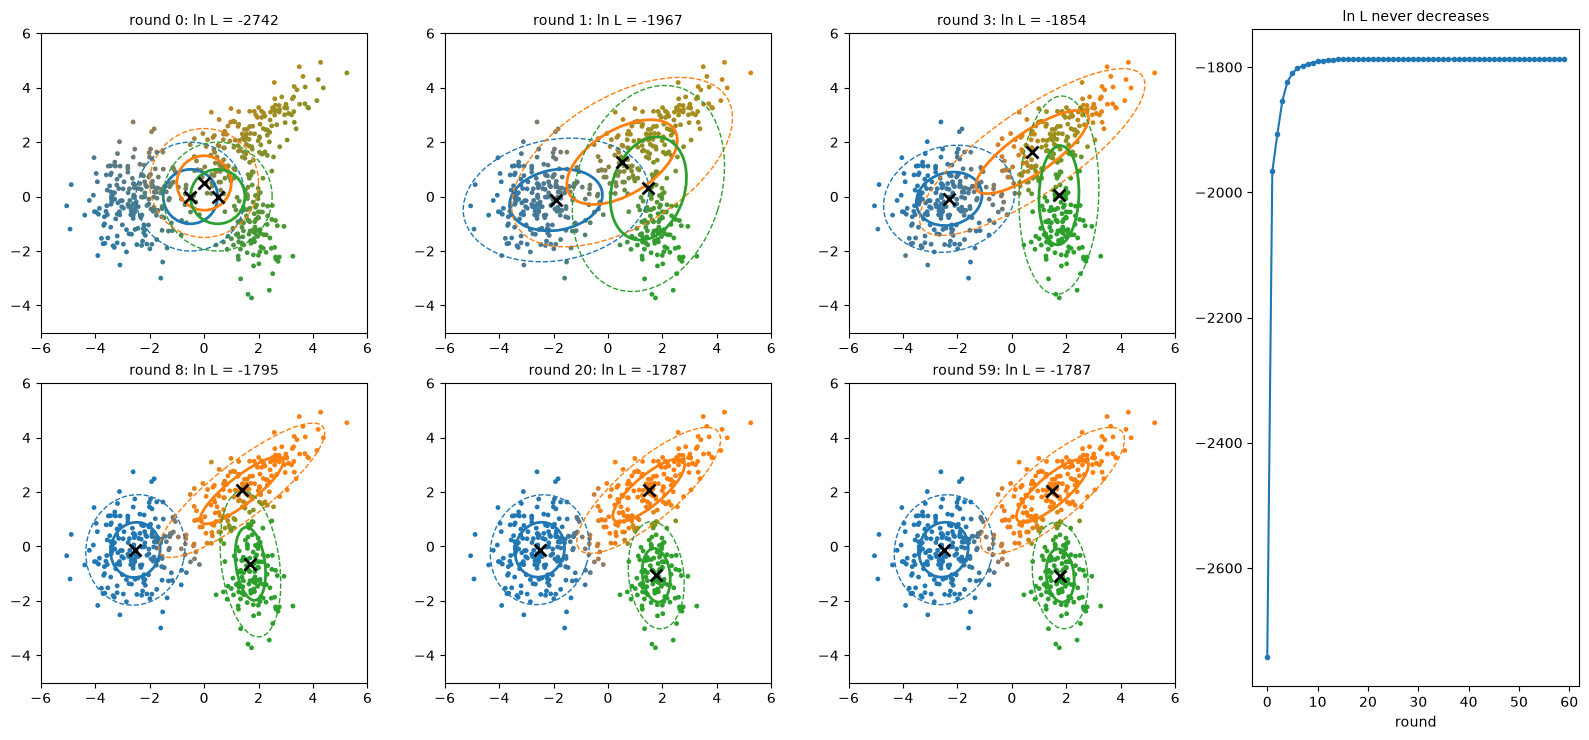

In [7]:
weights = np.full(3, 1 / 3)
means = np.array([[-0.5, 0.0], [0.0, 0.5], [0.5, 0.0]])
covariances = np.array([np.eye(2)] * 3)
history, log_likelihoods = [], []
for iteration in range(60):
    responsibilities, log_likelihood = e_step(X, weights, means, covariances)
    history.append((means, covariances, responsibilities))
    log_likelihoods.append(log_likelihood)
    weights, means, covariances = m_step(X, responsibilities)

fig = plt.figure(figsize=(16, 7.5))
for position, iteration in enumerate([0, 1, 3, 8, 20, 59]):
    ax = fig.add_subplot(2, 4, position + 1 + (position >= 3))
    step_means, step_covariances, step_responsibilities = history[iteration]
    ax.scatter(X[:, 0], X[:, 1], s=6, c=np.clip(step_responsibilities @ np.array(COLORS[:3]), 0, 1))
    for k in range(3):
        draw_ellipse(ax, step_means[k], step_covariances[k], COLORS[k])
        ax.plot(*step_means[k], "kx", ms=8, mew=2)
    ax.set_title(f"round {iteration}: ln L = {log_likelihoods[iteration]:.0f}")
    ax.set_xlim(-6, 6)
    ax.set_ylim(-5, 6)
    ax.set_aspect("equal")
ax = fig.add_subplot(1, 4, 4)
ax.plot(log_likelihoods, "o-", ms=3)
ax.set_xlabel("round")
ax.set_title("ln L never decreases")
fig.tight_layout()
plt.show()

After one round the components have moved apart, after a handful they have found the three groups, and from about round 20 on nothing changes any more: the curve is flat. The final ellipses sit almost exactly on the true ones of section 2.

### The same with scikit-learn

`GaussianMixture(n_components=3)` fits the same model with the same algorithm, but starts from a k-means solution instead of our bad guess. Its components come out in arbitrary order, so `matching(fitted_means)` pairs every true component with the nearest fitted mean before we print the three side by side. `model.score(X)` is scikit-learn's average log-likelihood per point; times the number of points it is $\ln L$.

In [8]:
fitted = GaussianMixture(n_components=3, random_state=SEED).fit(X)


def matching(fitted_means):
    return [int(np.argmin(np.linalg.norm(fitted_means - mean, axis=1))) for mean in TRUE_MEANS]


ours, theirs = matching(means), matching(fitted.means_)
print(f"{'':10}{'truth':>18}{'our EM':>18}{'scikit-learn':>18}")
for k in range(3):
    print(f"weight {k}  {TRUE_WEIGHTS[k]:>18.3f}{weights[ours[k]]:>18.3f}{fitted.weights_[theirs[k]]:>18.3f}")
    print(f"mean {k}    {str(TRUE_MEANS[k].round(2)):>18}{str(means[ours[k]].round(2)):>18}"
          f"{str(fitted.means_[theirs[k]].round(2)):>18}")
print(f"\nln L: our EM {log_likelihoods[-1]:.1f}, scikit-learn {fitted.score(X) * len(X):.1f}")
print(f"share of the points each component really generated: {np.bincount(true_component) / len(X)}")

                       truth            our EM      scikit-learn
weight 0               0.450             0.401             0.408
mean 0           [-2.5  0. ]     [-2.51 -0.12]     [-2.48 -0.12]
weight 1               0.350             0.362             0.347
mean 1             [1.5 2. ]       [1.49 2.05]       [1.55 2.12]
weight 2               0.200             0.237             0.245
mean 2           [ 1.8 -1.2]     [ 1.78 -1.07]     [ 1.76 -1.01]

ln L: our EM -1787.5, scikit-learn -1787.9
share of the points each component really generated: [0.4   0.366 0.234]


Our transcription and scikit-learn land on practically the same solution: weights within about 0.015 of each other, means within about 0.07, and a log-likelihood that differs by less than one unit. The small differences come from their different starting points and stopping rules. Both differ from the truth by about as much as 500 random points allow. The last printed line shows how many points each component really contributed to *this* sample (0.40, 0.37, 0.23), and the estimated weights follow those shares rather than the weights we sampled with (0.45, 0.35, 0.20). More data would bring them closer.

## 4. Soft assignments and RAPTOR's threshold

`predict_proba(X)` returns the fitted model's responsibilities: one row per point, one column per component, every row adding up to 1. RAPTOR turns them into memberships with a threshold – node *i* joins every cluster *k* with $r_{ik} > 0.1$ – whereas `predict(X)` would give the hard alternative, the single component with the largest responsibility. (We reorder the columns with `matching` so that the colours match the earlier figures.)

Three views of the soft assignment:

- left: every point coloured by its responsibilities, a weighted mix of the component colours; ringed points have a responsibility above the threshold for two or more components;
- middle: the largest responsibility of every point (note the logarithmic count axis);
- right: the share of points in two or more clusters, as a function of the threshold.

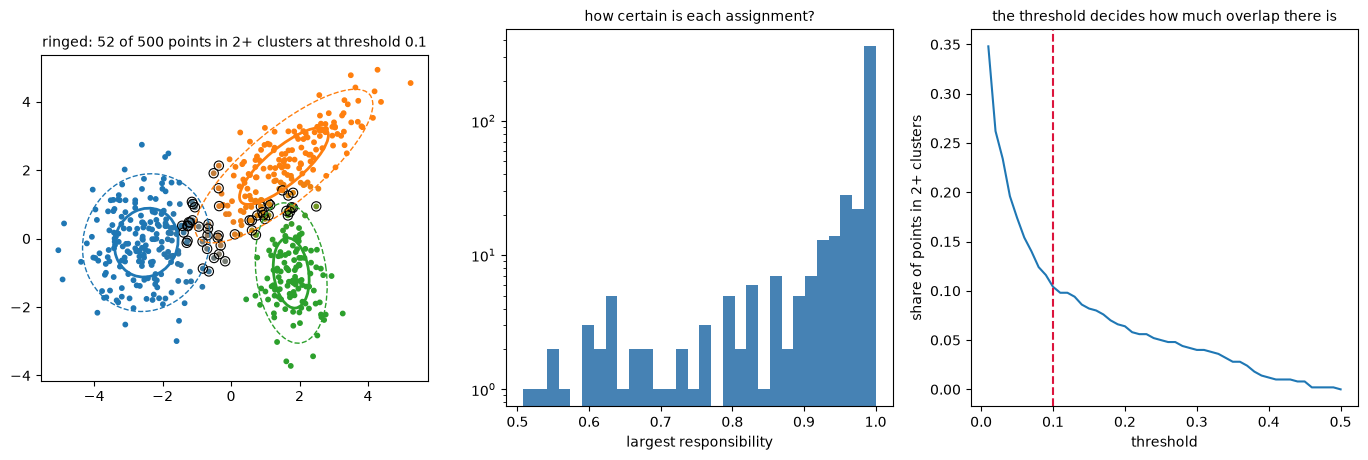

In [9]:
responsibilities = fitted.predict_proba(X)[:, theirs]
memberships = (responsibilities > THRESHOLD).sum(axis=1)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.9))
axes[0].scatter(X[:, 0], X[:, 1], s=10, c=np.clip(responsibilities @ np.array(COLORS[:3]), 0, 1))
axes[0].scatter(X[memberships > 1, 0], X[memberships > 1, 1], s=45, facecolors="none", edgecolors="black", lw=0.8)
for color, k in zip(COLORS, theirs):
    draw_ellipse(axes[0], fitted.means_[k], fitted.covariances_[k], color)
axes[0].set_aspect("equal")
axes[0].set_title(f"ringed: {(memberships > 1).sum()} of {len(X)} points in 2+ clusters at threshold {THRESHOLD}")
axes[1].hist(responsibilities.max(axis=1), bins=30, color="steelblue")
axes[1].set_yscale("log")
axes[1].set_xlabel("largest responsibility")
axes[1].set_title("how certain is each assignment?")
thresholds = np.linspace(0.01, 0.5, 50)
axes[2].plot(thresholds, [((responsibilities > t).sum(axis=1) > 1).mean() for t in thresholds])
axes[2].axvline(THRESHOLD, color="crimson", ls="--")
axes[2].set_xlabel("threshold")
axes[2].set_ylabel("share of points in 2+ clusters")
axes[2].set_title("the threshold decides how much overlap there is")
plt.show()

Most points are certain – their largest responsibility is close to 1 – and the uncertain ones sit exactly where two ellipses overlap. At RAPTOR's threshold of 0.1 roughly one point in ten belongs to two clusters. A lower threshold increases the overlap quickly; at 0.5 and above no point can be in two clusters, because two responsibilities above 0.5 would add up to more than 1.

## 5. Why not k-means?

k-means assigns every point to the nearest centre and moves every centre to the mean of its points. It is a mixture model with three restrictions: hard assignments, round clusters (spherical covariances), and all clusters of the same size. On elongated groups that matters. The data below is scikit-learn's standard example for this: three blobs, stretched and sheared by a linear transformation.

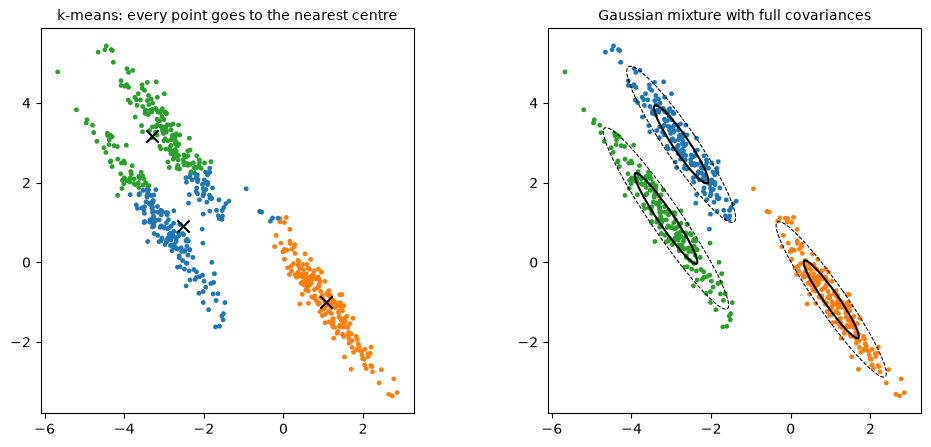

In [10]:
elongated, _ = make_blobs(n_samples=600, centers=3, random_state=170)
elongated = elongated @ np.array([[0.6, -0.64], [-0.41, 0.85]])
kmeans = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(elongated)
mixture = GaussianMixture(n_components=3, random_state=SEED).fit(elongated)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(elongated[:, 0], elongated[:, 1], s=6, c=[COLORS[c] for c in kmeans.labels_])
axes[0].scatter(*kmeans.cluster_centers_.T, color="black", marker="x", s=80)
axes[0].set_title("k-means: every point goes to the nearest centre")
axes[1].scatter(elongated[:, 0], elongated[:, 1], s=6, c=[COLORS[c] for c in mixture.predict(elongated)])
for k in range(3):
    draw_ellipse(axes[1], mixture.means_[k], mixture.covariances_[k], "black", lw=1.5)
axes[1].set_title("Gaussian mixture with full covariances")
for ax in axes:
    ax.set_aspect("equal")
plt.show()

k-means cuts the two parallel groups on the left across: measured by distance to a centre, the end of one group is closer to the middle of its neighbour. The mixture learns that every group is a long, tilted ellipse and recovers all three. Reduced embeddings rarely form round clusters, which is one reason RAPTOR uses a mixture.

## 6. Covariance types: how much shape to allow

scikit-learn offers four kinds of covariance (`covariance_type`):

- `full` – every component has its own arbitrary ellipse (scikit-learn's default, and what RAPTOR uses);
- `tied` – all components share one ellipse;
- `diag` – every component has its own ellipse, but aligned with the coordinate axes;
- `spherical` – every component is a circle with its own radius.

Fewer shape parameters make the model more robust when data is scarce, at the price of flexibility. The titles give each model's number of free parameters and its BIC (lower is better). The parameter count is read back out of scikit-learn's own BIC, which notebook 5c explains: since BIC = *p* · ln *n* − 2 · ln *L*, the count is *p* = (BIC + 2 · ln *L*) / ln *n*. `as_matrices(model)` converts scikit-learn's compact storage of the four types into full 2 × 2 matrices, so that `draw_ellipse` can draw them.

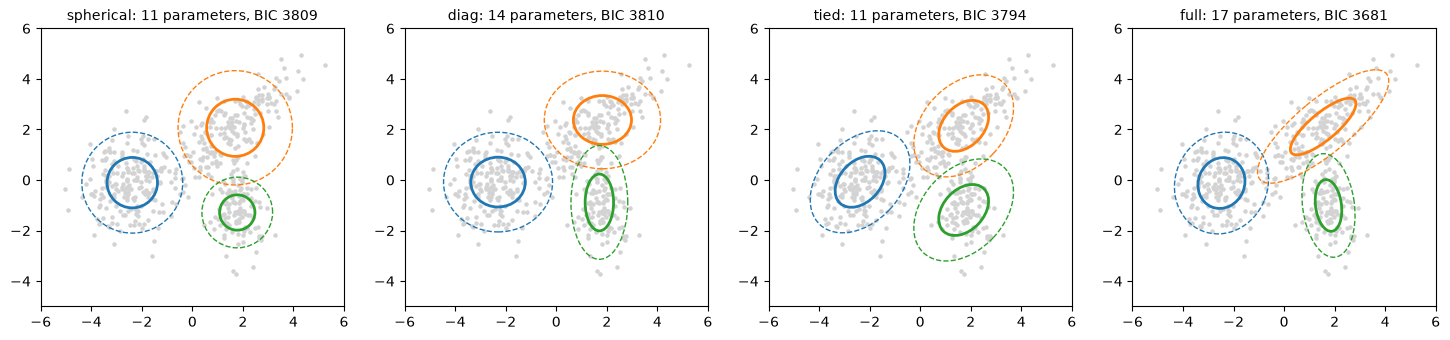

In [11]:
def as_matrices(model):
    if model.covariance_type == "full":
        return model.covariances_
    if model.covariance_type == "tied":
        return [model.covariances_] * model.n_components
    if model.covariance_type == "diag":
        return [np.diag(v) for v in model.covariances_]
    return [np.eye(model.means_.shape[1]) * v for v in model.covariances_]


fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
for ax, covariance_type in zip(axes, ["spherical", "diag", "tied", "full"]):
    model = GaussianMixture(n_components=3, covariance_type=covariance_type, random_state=SEED).fit(X)
    parameters = (model.bic(X) + 2 * model.score(X) * len(X)) / np.log(len(X))
    matrices = as_matrices(model)
    ax.scatter(X[:, 0], X[:, 1], s=5, color="lightgray")
    for color, k in zip(COLORS, matching(model.means_)):
        draw_ellipse(ax, model.means_[k], matrices[k], color)
    ax.set_title(f"{covariance_type}: {parameters:.0f} parameters, BIC {model.bic(X):.0f}")
    ax.set_xlim(-6, 6)
    ax.set_ylim(-5, 6)
    ax.set_aspect("equal")
plt.show()

All four find the three groups, but only `full` reproduces the tilted component, and it has the lowest BIC despite having the most parameters: here the extra shape is worth its price. With many dimensions, or with a handful of points per cluster, this trade-off can flip – that is the subject of notebook 5c.

## 7. Real data: the 30 leaves of notebook 5

Finally, the leaves of notebook 5's tree. The cell rebuilds them exactly like notebook 5 – same clean-up, heading-aware splitting into 1,200-character pieces, breadcrumbs – and embeds them. `short_label` turns every leaf's heading path into a short name such as "N4 Long-term Debt" or "N1 Income Taxes", so that the plot can be read.

Then UMAP reduces the leaves to 2 dimensions so that we can draw the mixture (RAPTOR uses 10). `n_neighbors` follows the paper's rule for its global step, int(√(*n* − 1)), which is 5 for 30 leaves.

In [12]:
text = DATA_FILE.read_text(encoding="utf-8").replace("\\$", "$")
text = "\n".join(line for line in text.splitlines() if line.strip() != "---")
headers = [("#", "h1"), ("##", "h2"), ("###", "h3"), ("####", "h4")]
splitter = RecursiveCharacterTextSplitter(
    chunk_size=CHUNK_SIZE,
    chunk_overlap=0,
    separators=["\n\n", "\n", r"(?<=</tr>)", r"(?<=\. )", " ", ""],
    is_separator_regex=True,
)
sections = MarkdownHeaderTextSplitter(headers_to_split_on=headers).split_text(text)
pieces = [p for p in splitter.split_documents(sections) if len(p.page_content) >= MIN_CHARS]


def breadcrumb(metadata):
    return " > ".join(metadata[k] for k in ("h1", "h2", "h3", "h4") if k in metadata)


def short_label(metadata):
    if metadata.get("h2") != "Notes to Financial Statements":
        return metadata.get("h3", metadata["h2"])
    note = metadata["h3"].split(" - ")[0].replace("Note ", "N")
    return f"{note} {metadata.get('h4', metadata['h3'].split(' - ')[1])}"


leaves = [f"{breadcrumb(p.metadata)}\n\n{p.page_content}" for p in pieces]
names = [short_label(p.metadata) for p in pieces]
leaf_vectors = np.array(OllamaEmbeddings(model=EMBEDDING_MODEL).embed_documents(leaves))
print(f"{len(leaves)} leaves, vectors of shape {leaf_vectors.shape}")

n_neighbors = int((len(leaves) - 1) ** 0.5)
leaves_2d = umap.UMAP(n_neighbors=n_neighbors, metric="cosine", random_state=SEED, n_jobs=1).fit_transform(leaf_vectors)
print(f"UMAP to 2 dimensions with n_neighbors = {n_neighbors}")

30 leaves, vectors of shape (30, 768)
UMAP to 2 dimensions with n_neighbors = 5


Now a mixture with five components. Here the number is simply given; where it comes from is the topic of notebook 5c. Left: the leaves in the UMAP map, coloured by their most likely component, together with the components' ellipses; red rings mark leaves above the threshold for two components. Right: the complete matrix of responsibilities, one row per leaf, sorted by component (`np.lexsort` sorts by the last key first: component, then decreasing certainty).

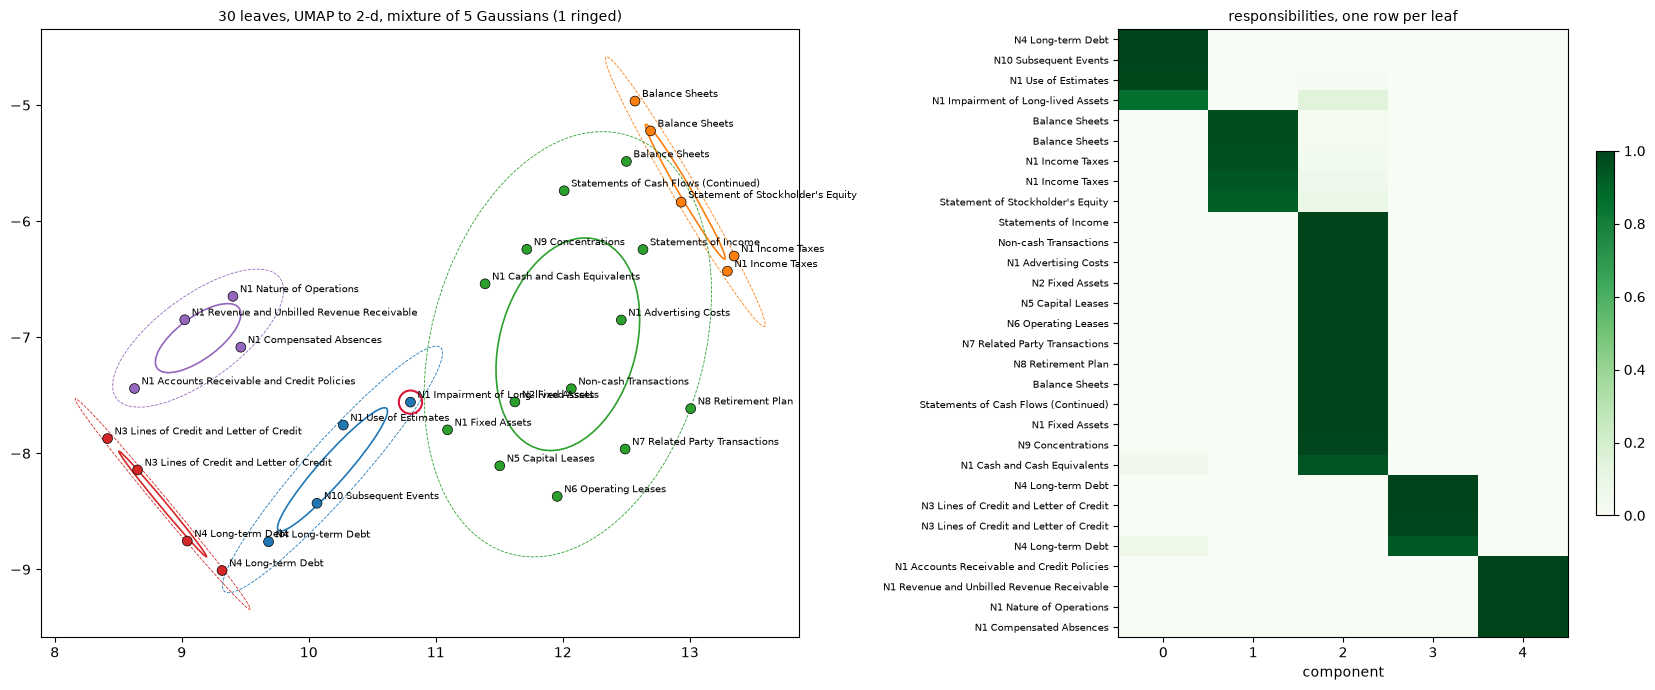

In [13]:
leaf_model = GaussianMixture(n_components=5, n_init=5, random_state=SEED).fit(leaves_2d)
leaf_responsibilities = leaf_model.predict_proba(leaves_2d)
hard = leaf_responsibilities.argmax(axis=1)
in_several = (leaf_responsibilities > THRESHOLD).sum(axis=1) > 1

fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={"width_ratios": [1.35, 1]})
for k in range(leaf_model.n_components):
    draw_ellipse(axes[0], leaf_model.means_[k], leaf_model.covariances_[k], COLORS[k], lw=1.2)
axes[0].scatter(leaves_2d[:, 0], leaves_2d[:, 1], c=[COLORS[k] for k in hard], s=50, edgecolor="black", lw=0.5)
axes[0].scatter(leaves_2d[in_several, 0], leaves_2d[in_several, 1], s=280, facecolors="none", edgecolors="crimson", lw=1.5)
for point, name in zip(leaves_2d, names):
    axes[0].annotate(name, point, textcoords="offset points", xytext=(5, 3), fontsize=7)
axes[0].set_title(f"{len(leaves)} leaves, UMAP to 2-d, mixture of 5 Gaussians ({in_several.sum()} ringed)")
order = np.lexsort((-leaf_responsibilities.max(axis=1), hard))
image = axes[1].imshow(leaf_responsibilities[order], aspect="auto", cmap="Greens", vmin=0, vmax=1)
axes[1].set_yticks(range(len(leaves)))
axes[1].set_yticklabels([names[i] for i in order], fontsize=7)
axes[1].set_xticks(range(leaf_model.n_components))
axes[1].set_xlabel("component")
axes[1].set_title("responsibilities, one row per leaf")
fig.colorbar(image, ax=axes[1], shrink=0.6)
fig.tight_layout()
plt.show()

The components follow topics rather than the order of the document: the lines of credit and the long-term debt end up together, and so do the nature of the company's operations, its revenue recognition and its receivables. The heatmap is almost black and white. On tight, well-separated UMAP clumps nearly every leaf belongs to one component with a probability near 1, and hardly any leaf crosses the threshold for a second one. That is typical of UMAP output, which pulls groups apart; on PCA output or on overlapping clusters like those of section 4, soft membership matters much more.

## Things to try

1. In section 3, start EM from three random data points instead of the centre (`means = X[rng.choice(len(X), 3, replace=False)]`). Does it always find the same solution? Try a few seeds.
2. Move `TRUE_MEANS[2]` towards component 1 and re-run sections 2–4. How do the responsibilities and the number of ringed points change?
3. Fit the 30 leaves with `covariance_type="spherical"` instead of `"full"`. Do the components change?
4. Replace the UMAP reduction of section 7 by `PCA(n_components=2)`. Are the responsibilities still black and white?
5. Lower `THRESHOLD` to 0.02. Which leaves join a second cluster, and does that make sense for their content?